# Task 1 · EDA on Retail Sales Data

**Objective:** Perform a thorough Exploratory Data Analysis on a retail sales dataset to uncover patterns, customer behaviour trends, and actionable business insights.

**Tech Stack:** Python, pandas, matplotlib, seaborn, Jupyter Notebook

**Dataset:** `retail_sales_data.csv` — 6,000 transactions from a multi-category retail store (Jan 2023 – Dec 2024), covering order date, customer demographics, product category, quantity, price, discount and sales.

In [ ]:
# Import  Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
#load dataset
df = pd.read_csv("retail_sales_data.csv", parse_dates=["OrderDate"])
df.head()

,OrderID,OrderDate,CustomerID,CustomerAge,CustomerGender,Region,Category,Product,Quantity,UnitPrice,Discount,Sales
0,100000,2024-06-18,10071,45.0,Male,West,Clothing,Cap,2,36.50,0.00,73.00
1,100001,2023-12-02,10277,44.0,Male,North,Electronics,Smartwatch,2,128.41,0.15,218.30
2,100002,2024-10-12,10099,37.0,Female,East,Home & Kitchen,Lamp,5,85.99,0.00,429.95
3,100003,2024-04-08,10850,35.0,Male,North,Electronics,Laptop,4,733.77,0.05,2788.33
4,100004,2023-02-13,10131,29.0,Male,South,Electronics,Speaker,5,464.39,0.20,1857.56


In [2]:
print(df.head().to_string())

   OrderID  OrderDate  CustomerID  CustomerAge CustomerGender Region        Category     Product  Quantity  UnitPrice  Discount    Sales
0   100000 2024-06-18       10071         45.0           Male   West        Clothing         Cap         2      36.50      0.00    73.00
1   100001 2023-12-02       10277         44.0           Male  North     Electronics  Smartwatch         2     128.41      0.15   218.30
2   100002 2024-10-12       10099         37.0         Female   East  Home & Kitchen        Lamp         5      85.99      0.00   429.95
3   100003 2024-04-08       10850         35.0           Male  North     Electronics      Laptop         4     733.77      0.05  2788.33
4   100004 2023-02-13       10131         29.0           Male  South     Electronics     Speaker         5     464.39      0.20  1857.56

## 1. Initial Inspection

In [26]:
print("Shape:", df.shape)
print("Column dtypes:\n", df.dtypes)


Shape: (6000, 15)
Column dtypes:
 OrderID                    int64
OrderDate         datetime64[us]
CustomerID                 int64
CustomerAge              float64
CustomerGender               str
Region                       str
Category                     str
Product                      str
Quantity                   int64
UnitPrice                float64
Discount                 float64
Sales                    float64
YearMonth                    str
YearQuarter                  str
Weekday                      str
dtype: object


In [27]:
print("Null values per column:\n", df.isnull().sum())

Null values per column:
 OrderID            0
OrderDate          0
CustomerID         0
CustomerAge       25
CustomerGender     0
Region             0
Category           0
Product            0
Quantity           0
UnitPrice          0
Discount           0
Sales              0
YearMonth          0
YearQuarter        0
Weekday            0
dtype: int64


There are a handful of missing `CustomerAge` values (25 out of 6,000). Everything else is fully populated. We'll drop these rows for the demographic charts only, since imputing age would distort the age-distribution insight.

## 2. Descriptive Statistics

In [ ]:
#Descriptive Statistics(Mean,Median,Mode,Standard Devation)
numeric_cols = ["CustomerAge", "Quantity", "UnitPrice", "Discount", "Sales"]
desc = df[numeric_cols].agg(["mean", "median", lambda x: x.mode().iloc[0], "std"]).T
desc.columns = ["mean", "median", "mode", "std"]
print(desc.round(2))

               mean  median   mode     std
CustomerAge   42.60   42.00  38.00   15.47
Quantity       3.00    3.00   3.00    1.41
UnitPrice    188.21   81.27  12.98  230.88
Discount       0.07    0.05   0.00    0.07
Sales        512.04  213.96  39.14  727.01


## 3. Time Series Analysis — Monthly & Quarterly Sales Trends

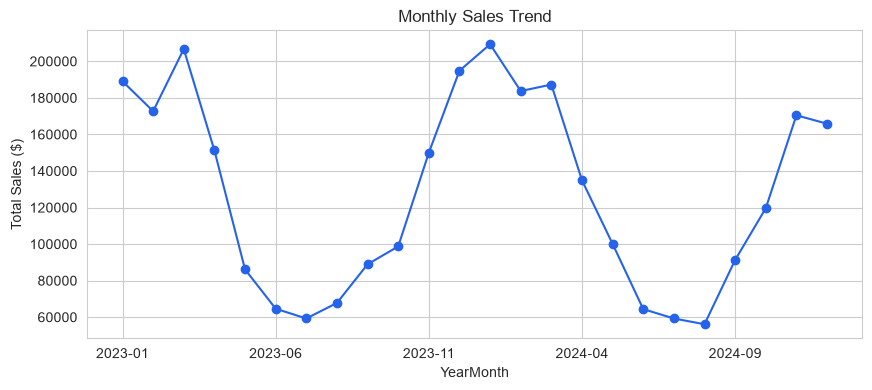

In [ ]:

# Create the Year-Month column and add up the sales
df["YearMonth"] = df["OrderDate"].dt.to_period("M").astype(str)
monthly_sales = df.groupby("YearMonth")["Sales"].sum()

# Draw the line chart
monthly_sales.plot(
    kind="line", 
    marker="o", 
    color="#2563eb", 
    figsize=(10, 4), 
    title="Monthly Sales Trend", 
    ylabel="Total Sales ($)"
)
plt.show()

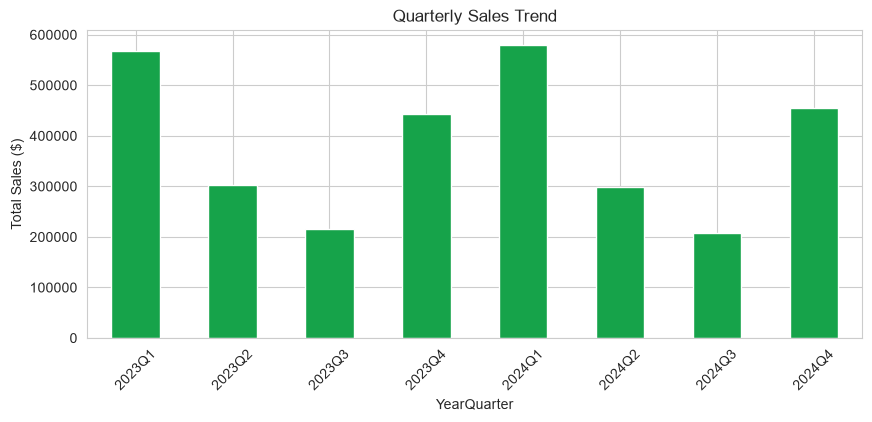

In [51]:
# Create the Year-Quarter column and add up the sales
df["YearQuarter"] = df["OrderDate"].dt.to_period("Q").astype(str)
quarterly_sales = df.groupby("YearQuarter")["Sales"].sum()

# Draw the bar chart
quarterly_sales.plot(
    kind="bar", 
    color="#16a34a", 
    figsize=(10, 4), 
    title="Quarterly Sales Trend", 
    ylabel="Total Sales ($)"
)
plt.xticks(rotation=45) # Tilts the quarter labels so they don't overlap
plt.show()

**Observation:** Sales show a clear seasonal wave, peaking in Q4 (Oct–Dec) — consistent with the holiday shopping season — and dipping in the middle of the year. This pattern repeats across both years in the dataset, suggesting a genuine seasonal cycle rather than a one-off event.

## 4. Customer Demographics Analysis

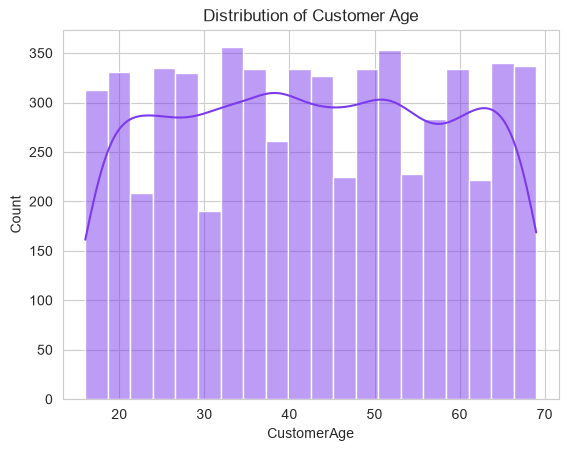

In [ ]:
# Draw the age distribution with a smooth curve (kde)
sns.histplot(df["CustomerAge"].dropna(), bins=20, kde=True, color="#7c3aed",)
# Add title and display
plt.title("Distribution of Customer Age")
plt.show()

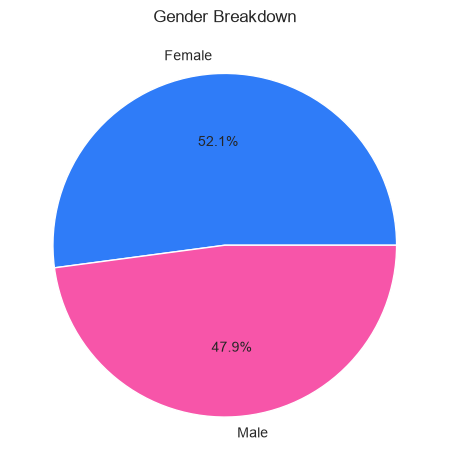

In [54]:
import matplotlib.pyplot as plt

# Count the genders and plot a pie chart instantly
df["CustomerGender"].value_counts().plot(
    kind="pie", 
    autopct="%1.1f%%",          # Shows the percentages
    colors=["#2f7cf8", "#f755a9"], 
    title="Gender Breakdown",
    ylabel=""                   # Hides the ugly default side label
)
plt.tight_layout()
plt.show()

**Observation:** Customer ages cluster between 25–55 with a fairly even, slightly right-skewed spread — there's no single dominant age bracket. The gender split is close to even (52% Female / 48% Male), so marketing doesn't need to be gender-skewed at the portfolio level.

## 5. Product Analysis — Top Products & Category Revenue

C:\Users\Ncs\AppData\Local\Temp\ipykernel_16672\94810372.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette="viridis")


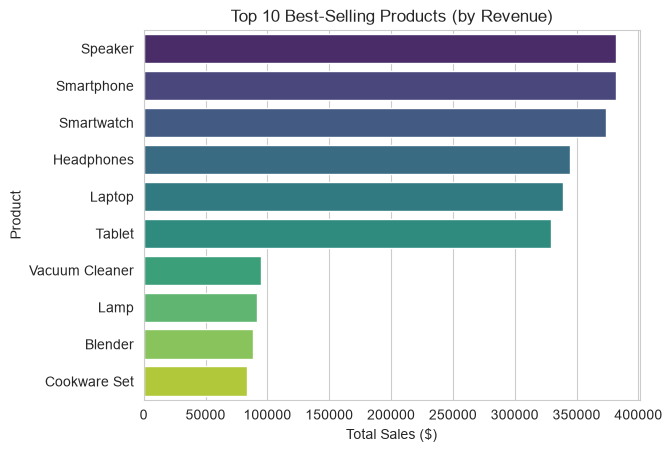

In [53]:
# Calculate the top 10 products
top_products = df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)
# Draw the chart
sns.barplot(x=top_products.values, y=top_products.index, palette="viridis")
plt.title("Top 10 Best-Selling Products (by Revenue)")
plt.xlabel("Total Sales ($)")
plt.show()

C:\Users\Ncs\AppData\Local\Temp\ipykernel_16672\2061977522.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_revenue.values, y=category_revenue.index, palette="crest")


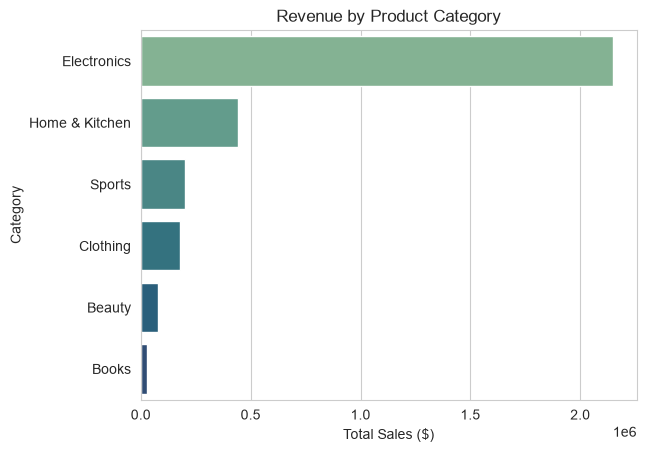

In [ ]:
# Calculate the sales per category
category_revenue = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
# Draw the chart
sns.barplot(x=category_revenue.values, y=category_revenue.index, palette="crest")
plt.title("Revenue by Product Category")
plt.xlabel("Total Sales ($)")
plt.show()

**Observation:** Electronics dominates category revenue despite lower unit volume — high price-points (laptops, smartphones) drive this. Clothing wins on volume but trails on total revenue, meaning basket-size/upsell strategies matter more there than traffic generation.

## 6. Correlation Heatmap

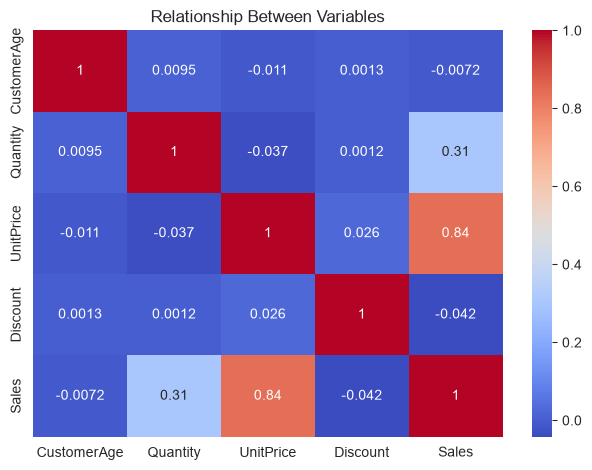

In [ ]:

# Calculate how these specific columns relate to each other
relationships = df[["CustomerAge", "Quantity", "UnitPrice", "Discount", "Sales"]].corr()
# Draw the color-coded heatmap
sns.heatmap(relationships, annot=True, cmap="coolwarm")
plt.title("Relationship Between Variables")
plt.tight_layout()
plt.show()

**Observation:** `UnitPrice` correlates most strongly with `Sales` (as expected), while `Discount` shows a weak relationship with `Sales` — discounts alone aren't a strong sales driver in this dataset. `CustomerAge` shows negligible correlation with any purchase metric, meaning age isn't predictive of spend.

## 7. Additional Insight — Sales by Region & Weekday

C:\Users\Ncs\AppData\Local\Temp\ipykernel_16672\2129932657.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_sales.index, y=region_sales.values, palette="flare")


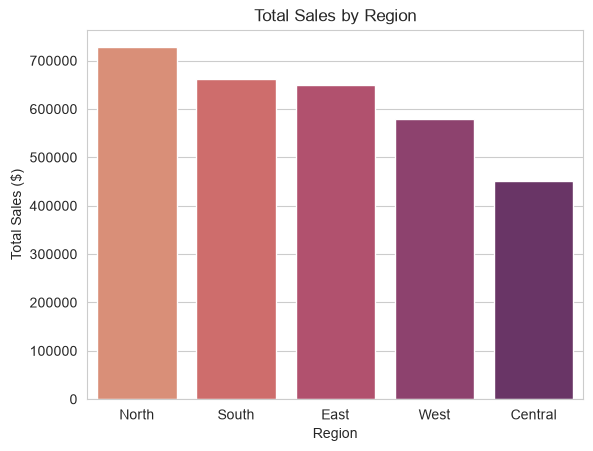

In [ ]:
# Add up the total sales for each region and sort them from highest to lowest
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
# Draw the bar chart
sns.barplot(x=region_sales.index, y=region_sales.values, palette="flare")
plt.title("Total Sales by Region")
plt.ylabel("Total Sales ($)")
plt.show()

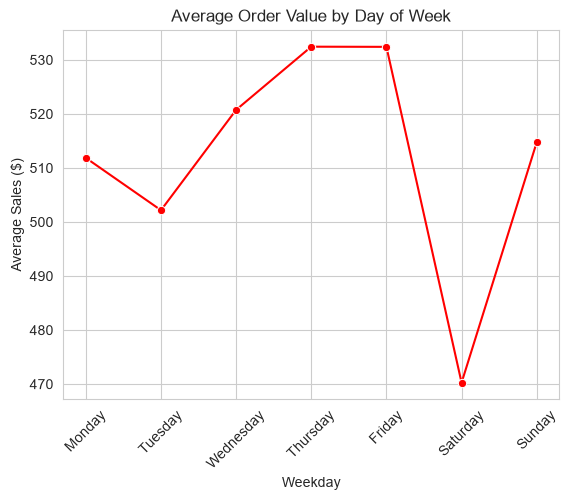

In [ ]:
# Figure out what day of the week each order happened
df["Weekday"] = df["OrderDate"].dt.day_name()

# Tell the computer the correct order of a week
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Calculate the average sale size for each day, keeping them in the correct order
weekday_sales = df.groupby("Weekday")["Sales"].mean().reindex(weekday_order)

# Draw the line chart
sns.lineplot(x=weekday_sales.index, y=weekday_sales.values, marker="o", color="red")
plt.title("Average Order Value by Day of Week")
plt.ylabel("Average Sales ($)")
plt.xticks(rotation=45) # Tilts the day names so they fit nicely
plt.show()

**Observation (non-obvious insight):** The North region leads in total sales, but average order value peaks on weekends — customers who shop Saturday/Sunday spend more per order than weekday shoppers, even though weekday order *counts* are similar. This points to weekend shoppers being more considered/higher-intent buyers.

## 8. Conclusion — Actionable Business Recommendations

Based on the analysis above:

1. **Double down on Q4 inventory and marketing spend.** Sales consistently peak in Oct–Dec across both years — increase Electronics and Clothing stock ahead of this window and shift ad budget earlier (Sept) to capture early holiday shoppers.
2. **Re-price the discount strategy.** Discount level shows only a weak correlation with total Sales, suggesting current promotions aren't efficiently driving revenue. A/B test smaller, targeted discounts (e.g., bundle deals) against blanket percentage-off discounts to protect margin.
3. **Push weekend-specific premium offers.** Since average order value is highest on weekends, feature higher-margin/premium products in weekend email campaigns and consider weekend-only bundles to capture this higher-intent segment, rather than spreading the same promotions evenly across the week.